# Previsão de lotação da academia com LSTM

Este notebook prepara a série de lotação de uma academia universitária, compara janelas de histórico para uma rede LSTM e avalia a melhor configuração contra previsões de referência. A previsão é de um passo à frente: a lotação média da próxima hora.

## 1. Configuração

O notebook roda no Google Colab sem instalar nada: todas as bibliotecas usadas já vêm no ambiente. O dataset é público, então o download não exige credenciais do Kaggle, e o arquivo é conferido pelo hash SHA-256 para que todos usem exatamente os mesmos dados.

**Passos de configuração no Colab:**
1. Em *Ambiente de execução > Alterar o tipo de ambiente de execução*, escolha uma GPU. O treino também roda em CPU, mas fica bem mais lento.
2. Use *Ambiente de execução > Executar tudo*.

A variável `FAST_RUN` serve só para verificações rápidas durante o desenvolvimento. Ela fica desligada na execução entregue.

In [1]:
import hashlib
import io
import os
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import acf

DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/nsrose7224/crowdedness-at-the-campus-gym"
DATASET_SHA256 = "490412204d0d90c58036788adaaba1a16968dfab525fad3fefe78a18bc998ff4"
LOCAL_DATASET_PATHS = [Path("data/raw/data.csv"), Path("../data/raw/data.csv")]

FAST_RUN = os.environ.get("FAST_RUN") == "1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FILL_LIMIT_HOURS = 8
MIN_READINGS_PER_HOUR = 3
MAX_READINGS_PER_HOUR = 12
CONTINUOUS_WINDOWS = [24, 168]

BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
MAGENTA = "#e87ba4"
GREEN = "#008300"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
MUTED_INK = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "xtick.color": MUTED_INK,
    "ytick.color": MUTED_INK,
    "text.color": SECONDARY_INK,
    "legend.frameon": False,
    "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
def read_verified_dataset():
    for path in LOCAL_DATASET_PATHS:
        if path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest() == DATASET_SHA256:
            return pd.read_csv(path)
    request = urllib.request.Request(DATASET_URL, headers={"User-Agent": "dataset-ingest"})
    with urllib.request.urlopen(request, timeout=120) as response:
        archive_content = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_content)) as archive:
        csv_content = archive.read("data.csv")
    if hashlib.sha256(csv_content).hexdigest() != DATASET_SHA256:
        raise ValueError("O arquivo baixado difere da versão validada do dataset")
    output_path = LOCAL_DATASET_PATHS[0]
    output_path.parent.mkdir(parents=True, exist_ok=True)
    output_path.write_bytes(csv_content)
    return pd.read_csv(io.BytesIO(csv_content))


raw = read_verified_dataset()
print(f"{raw.shape[0]} linhas e {raw.shape[1]} colunas")
raw.head()

62184 linhas e 11 colunas


,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


## 2. Problema e dataset

| Item | Descrição |
|---|---|
| **Dataset** | Crowdedness at the Campus Gym |
| **Fonte** | [Kaggle, publicado por nsrose7224](https://www.kaggle.com/datasets/nsrose7224/crowdedness-at-the-campus-gym) |
| **Problema** | Prever quantas pessoas estarão na academia na próxima observação, para que os alunos escolham melhores horários e a gestão planeje a operação |
| **Variável-alvo** | `number_people`, número de pessoas presentes |
| **Frequência** | Leituras a cada 10 minutos, aproximadamente, agregadas em médias horárias na seção 3. A previsão é a lotação média da próxima hora |
| **Variáveis de apoio** | Calendário, feriados, início e período de semestre, e temperatura em graus Fahrenheit |

**Por que este dataset:** a lotação depende do histórico recente e de ciclos humanos, como a rotina do dia e da semana. Esse é o tipo de dependência temporal que uma LSTM pode aprender. A série também cobre mais de um ano e meio, o que permite separar treino, validação e teste em ordem cronológica.

In [3]:
local_clock = pd.to_datetime(raw["date"].str[:19])
column_overview = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "valores_distintos": raw.nunique(),
    "mínimo": raw.min(numeric_only=True),
    "máximo": raw.max(numeric_only=True),
})
calendar_agreement = {
    "hour": float((raw["hour"] == local_clock.dt.hour).mean()),
    "day_of_week": float((raw["day_of_week"] == local_clock.dt.day_of_week).mean()),
    "month": float((raw["month"] == local_clock.dt.month).mean()),
}
print(f"Período: {local_clock.min()} a {local_clock.max()}")
print(f"Linhas duplicadas: {raw.duplicated().sum()}")
print(f"Concordância das colunas de calendário com a data: {calendar_agreement}")
column_overview

Período: 2015-08-14 17:00:11 a 2017-03-18 19:22:51
Linhas duplicadas: 0
Concordância das colunas de calendário com a data: {'hour': 1.0, 'day_of_week': 1.0, 'month': 1.0}


,tipo,nulos,valores_distintos,mínimo,máximo
date,str,0,62184,NaN,NaN
day_of_week,int64,0,7,0.00,6.00
hour,int64,0,24,0.00,23.00
is_during_semester,int64,0,2,0.00,1.00
is_holiday,int64,0,2,0.00,1.00
is_start_of_semester,int64,0,2,0.00,1.00
is_weekend,int64,0,2,0.00,1.00
month,int64,0,12,1.00,12.00
number_people,int64,0,128,0.00,145.00
temperature,float64,0,2599,38.14,87.17


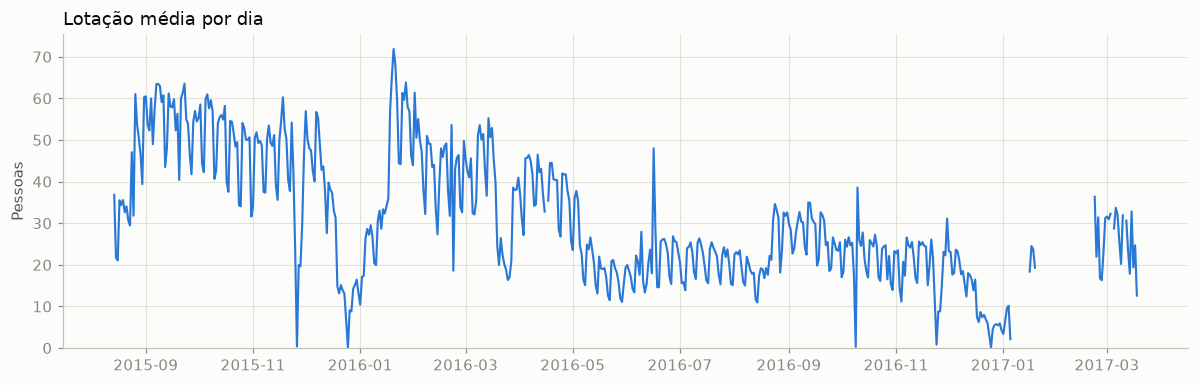

In [4]:
daily_mean = raw.assign(local_clock=local_clock).set_index("local_clock").sort_index()["number_people"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily_mean.index, daily_mean.values, color=BLUE, linewidth=1.4)
ax.set_title("Lotação média por dia")
ax.set_ylabel("Pessoas")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

In [5]:
assert raw.shape == (62184, 11)
assert list(raw.columns)[:2] == ["number_people", "date"]
assert raw["number_people"].min() >= 0
print("Dataset conferido")

Dataset conferido


## 3. Limpeza e preparação

### 3.1 Resolvendo a ordem cronológica das leituras

In [6]:
instants = pd.to_datetime(raw["date"], utc=True)
steps_back_in_time = instants.diff().dt.total_seconds() < 0

print(f"Leituras em ordem crescente: {instants.is_monotonic_increasing}")
print(f"Linhas com data anterior à da linha de cima: {steps_back_in_time.sum()}")
raw.loc[steps_back_in_time, ["date", "number_people"]]

Leituras em ordem crescente: False
Linhas com data anterior à da linha de cima: 1


,date,number_people
51178,2016-11-06 01:01:52-08:00,0


In [7]:
readings = (
    raw.assign(instant_utc=instants, local_time=local_clock)
    .sort_values("instant_utc")
    .reset_index(drop=True)
)

print(f"Leituras em ordem crescente após a ordenação: {readings['instant_utc'].is_monotonic_increasing}")

Leituras em ordem crescente após a ordenação: True


### 3.2 Resolvendo a amostragem irregular

In [8]:
interval_minutes = readings["instant_utc"].diff().dt.total_seconds().div(60).dropna()
interval_groups = pd.cut(
    interval_minutes,
    bins=[0, 15, 30, 60, 180, 720, np.inf],
    labels=["até 15 min", "15 a 30 min", "30 a 60 min", "1 a 3 h", "3 a 12 h", "acima de 12 h"],
)
interval_table = interval_groups.value_counts(sort=False).rename("intervalos").rename_axis("duração").to_frame()
interval_table["parcela_%"] = 100 * interval_table["intervalos"] / len(interval_minutes)

grid_rows = []
for rule in ["10min", "30min", "1h"]:
    grid = readings.set_index("local_time")["number_people"].resample(rule).mean()
    grid_rows.append({"grade": rule, "posições": len(grid), "posições_vazias_%": 100 * grid.isna().mean()})

print(f"Intervalo mediano entre leituras: {interval_minutes.median():.1f} min")
display(interval_table)
display(pd.DataFrame(grid_rows))

Intervalo mediano entre leituras: 10.0 min


,intervalos,parcela_%
duração,,
até 15 min,56756,91.27
15 a 30 min,4932,7.93
30 a 60 min,119,0.19
1 a 3 h,68,0.11
3 a 12 h,295,0.47
acima de 12 h,13,0.02


,grade,posições,posições_vazias_%
0,10min,83823,26.28
1,30min,27941,18.22
2,1h,13971,16.71


In [9]:
hour_groups = readings.set_index("local_time").resample("1h")
hourly = pd.DataFrame({
    "people_observed": hour_groups["number_people"].mean(),
    "n_readings": hour_groups["number_people"].count(),
    "temperature": hour_groups["temperature"].mean(),
    "is_during_semester": hour_groups["is_during_semester"].mean(),
})
hourly.index.name = "hour"

print(f"Grade horária: {len(hourly)} horas, de {hourly.index.min()} a {hourly.index.max()}")
print(f"Horas com pelo menos uma leitura: {(hourly['n_readings'] > 0).sum()}")
hourly.head()

Grade horária: 13971 horas, de 2015-08-14 17:00:00 a 2017-03-18 19:00:00
Horas com pelo menos uma leitura: 11637


,people_observed,n_readings,temperature,is_during_semester
hour,,,,
2015-08-14 17:00:00,42.20,5,71.76,0.00
2015-08-14 18:00:00,47.80,5,72.15,0.00
2015-08-14 19:00:00,39.80,5,69.97,0.00
2015-08-14 20:00:00,40.20,5,68.80,0.00
2015-08-14 21:00:00,44.80,5,68.04,0.00


### 3.3 Resolvendo horas com leituras insuficientes

In [10]:
observed_hours = hourly[hourly["n_readings"] > 0]
readings_by_month = observed_hours.groupby(observed_hours.index.to_period("M"))["n_readings"].agg(mediana="median", média="mean", máximo="max")
few_readings = observed_hours[observed_hours["n_readings"] < MIN_READINGS_PER_HOUR]
few_readings_by_hour = few_readings.groupby(few_readings.index.hour).size().reindex(range(24), fill_value=0)
busiest_hour = observed_hours["n_readings"].idxmax()
busiest_hour_context = hourly.loc[busiest_hour - pd.Timedelta(hours=1) : busiest_hour + pd.Timedelta(hours=1), ["people_observed", "n_readings"]]

print(f"Horas com menos de {MIN_READINGS_PER_HOUR} leituras: {len(few_readings)} ({100 * len(few_readings) / len(observed_hours):.2f}% das horas com leitura)")
print(f"Maior número de leituras em uma hora: {observed_hours['n_readings'].max()}, em {busiest_hour}")
display(readings_by_month)
display(few_readings_by_hour.rename("horas_com_poucas_leituras").to_frame().T)
display(busiest_hour_context)

Horas com menos de 3 leituras: 359 (3.08% das horas com leitura)


Maior número de leituras em uma hora: 98, em 2015-08-25 17:00:00


,mediana,média,máximo
hour,,,
2015-08,5.00,4.98,98
2015-09,5.00,4.67,5
2015-10,5.00,4.70,5
2015-11,5.00,4.72,7
2015-12,5.00,4.71,8
2016-01,5.00,4.69,5
2016-02,5.00,4.72,6
2016-03,5.00,4.67,8
2016-04,5.00,4.65,6


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
horas_com_poucas_leituras,7,252,0,0,5,3,2,2,6,8,...,2,9,1,5,5,2,4,5,4,16


,people_observed,n_readings
hour,,
2015-08-25 16:00:00,79.20,5
2015-08-25 17:00:00,9.19,98
2015-08-25 18:00:00,36.70,10


In [11]:
has_valid_readings = hourly["n_readings"].between(MIN_READINGS_PER_HOUR, MAX_READINGS_PER_HOUR)
discarded_hours = hourly.index[hourly["people_observed"].notna() & ~has_valid_readings]
hourly.loc[~has_valid_readings, "people_observed"] = np.nan

print(f"Horas descartadas: {len(discarded_hours)}")
print(f"Horas com observação válida: {hourly['people_observed'].notna().sum()}")
print(f"Média da hora da rajada depois da correção: {hourly.loc[busiest_hour, 'people_observed']}")

Horas descartadas: 360
Horas com observação válida: 11277
Média da hora da rajada depois da correção: nan


### 3.4 Resolvendo as lacunas noturnas de coleta

Lacunas acima de 3h: 308
Duração mediana: 4.3h | percentil 90: 7.4h


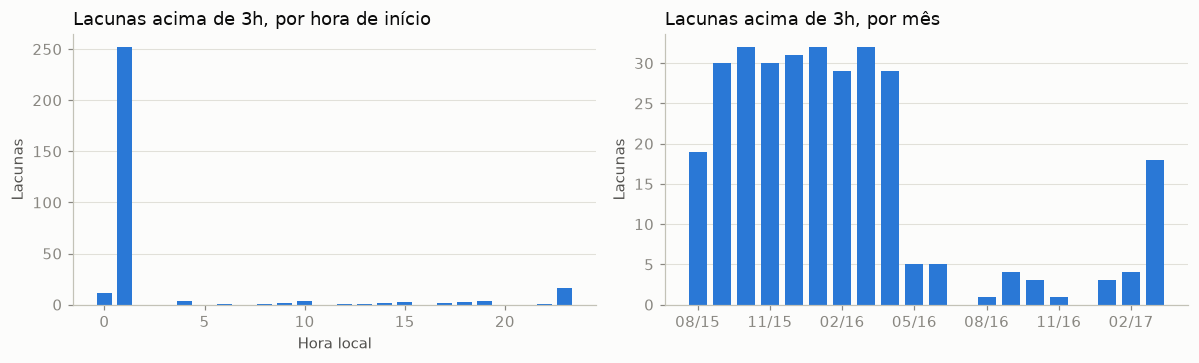

In [12]:
gap_hours = readings["instant_utc"].diff().dt.total_seconds().div(3600)
long_gaps = readings.assign(gap_hours=gap_hours, gap_start=readings["local_time"].shift(1)).query("gap_hours > 3")

gaps_by_start_hour = long_gaps["gap_start"].dt.hour.value_counts().reindex(range(24), fill_value=0)
all_months = pd.period_range(readings["local_time"].min(), readings["local_time"].max(), freq="M")
gaps_by_month = long_gaps.groupby(long_gaps["local_time"].dt.to_period("M")).size().reindex(all_months, fill_value=0)

print(f"Lacunas acima de 3h: {len(long_gaps)}")
print(f"Duração mediana: {long_gaps['gap_hours'].median():.1f}h | percentil 90: {long_gaps['gap_hours'].quantile(0.9):.1f}h")

fig, (hour_axis, month_axis) = plt.subplots(1, 2, figsize=(11, 3.4))
hour_axis.bar(gaps_by_start_hour.index, gaps_by_start_hour.values, color=BLUE, width=0.75)
hour_axis.set_title("Lacunas acima de 3h, por hora de início")
hour_axis.set_xlabel("Hora local")
hour_axis.set_ylabel("Lacunas")
hour_axis.grid(axis="x", visible=False)
month_positions = np.arange(len(gaps_by_month))
month_axis.bar(month_positions, gaps_by_month.values, color=BLUE, width=0.75)
month_axis.set_title("Lacunas acima de 3h, por mês")
month_axis.set_xticks(month_positions[::3], [month.strftime("%m/%y") for month in gaps_by_month.index[::3]])
month_axis.set_ylabel("Lacunas")
month_axis.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [13]:
def missing_run_lengths(series):
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    return is_missing.groupby(run_id).transform("sum").where(is_missing, 0).astype(int)


def complete_window_targets(observed, available, window):
    has_complete_window = available.astype(float).rolling(window).sum().shift(1).eq(window)
    return observed.notna() & has_complete_window


hourly["missing_run_hours"] = missing_run_lengths(hourly["people_observed"])

sensitivity_rows = []
for fill_limit in [0, 3, 6, 8, 12]:
    is_filled = hourly["missing_run_hours"].between(1, fill_limit)
    available = hourly["people_observed"].notna() | is_filled
    targets_by_window = {
        window: complete_window_targets(hourly["people_observed"], available, window)
        for window in CONTINUOUS_WINDOWS
    }
    sensitivity_rows.append({
        "limite_horas": fill_limit,
        "horas_preenchidas_%": 100 * is_filled.sum() / available.sum(),
        "alvos_janela_24h": int(targets_by_window[24].sum()),
        "alvos_janela_168h": int(targets_by_window[168].sum()),
        "alvos_comuns": int((targets_by_window[24] & targets_by_window[168]).sum()),
    })

hourly["is_imputed"] = hourly["missing_run_hours"].between(1, FILL_LIMIT_HOURS).astype(int)
hourly["is_available"] = hourly["people_observed"].notna() | hourly["is_imputed"].eq(1)
imputed_hours = hourly.index[hourly["is_imputed"] == 1]

print(f"Lacunas acima de 3h cobertas pelo limite de {FILL_LIMIT_HOURS}h: {100 * long_gaps['gap_hours'].le(FILL_LIMIT_HOURS).mean():.1f}%")
print(f"Horas marcadas como preenchidas: {len(imputed_hours)}, das quais {100 * imputed_hours.hour.isin(range(1, 7)).mean():.1f}% entre 1h e 6h")
pd.DataFrame(sensitivity_rows)

Lacunas acima de 3h cobertas pelo limite de 8h: 91.9%
Horas marcadas como preenchidas: 1204, das quais 89.1% entre 1h e 6h


,limite_horas,horas_preenchidas_%,alvos_janela_24h,alvos_janela_168h,alvos_comuns
0,0,0.00,5103,3233,3233
1,3,0.76,5642,4072,4072
2,6,9.28,10710,8478,8478
3,8,9.65,10854,9489,9489
4,12,10.19,10974,9657,9657


### 3.5 Resolvendo as lacunas longas do fim da série

In [14]:
is_empty = ~hourly["is_available"]
empty_run_id = (is_empty != is_empty.shift()).cumsum()[is_empty]
empty_runs = (
    pd.Series(hourly.index[is_empty], index=empty_run_id.values)
    .groupby(level=0)
    .agg(["min", "max", "size"])
    .rename(columns={"min": "início", "max": "fim", "size": "horas"})
    .sort_values("horas", ascending=False)
    .reset_index(drop=True)
)
empty_runs["dias"] = empty_runs["horas"] / 24

blocked_rows = []
for window in CONTINUOUS_WINDOWS:
    window_touches_gap = is_empty.astype(float).rolling(window, min_periods=1).sum().shift(1).gt(0)
    blocked_rows.append({
        "janela_horas": window,
        "alvos_observados": int(hourly["people_observed"].notna().sum()),
        "alvos_com_lacuna_na_janela": int((hourly["people_observed"].notna() & window_touches_gap).sum()),
    })

print(f"Lacunas acima de {FILL_LIMIT_HOURS}h: {len(empty_runs)}")
display(empty_runs.head(8))
display(pd.DataFrame(blocked_rows))

Lacunas acima de 8h: 22


,início,fim,horas,dias
0,2017-01-19 16:00:00,2017-02-22 12:00:00,813,33.88
1,2017-01-05 09:00:00,2017-01-16 20:00:00,276,11.50
2,2017-03-10 19:00:00,2017-03-12 17:00:00,47,1.96
3,2017-03-03 16:00:00,2017-03-05 10:00:00,43,1.79
4,2016-04-15 15:00:00,2016-04-17 09:00:00,43,1.79
5,2016-06-15 19:00:00,2016-06-17 12:00:00,42,1.75
6,2016-10-09 07:00:00,2016-10-10 08:00:00,26,1.08
7,2017-03-05 13:00:00,2017-03-06 08:00:00,20,0.83


,janela_horas,alvos_observados,alvos_com_lacuna_na_janela
0,24,11277,403
1,168,11277,1648


In [15]:
eligible_by_window = {
    window: complete_window_targets(hourly["people_observed"], hourly["is_available"], window)
    for window in CONTINUOUS_WINDOWS
}
common_targets = eligible_by_window[24] & eligible_by_window[168]
target_hours = hourly.index[common_targets]

print(f"Alvos com janela completa de 24h: {eligible_by_window[24].sum()}")
print(f"Alvos com janela completa de 168h: {eligible_by_window[168].sum()}")
print(f"Datas-alvo comuns às duas janelas: {len(target_hours)}")
print(f"Primeira e última data-alvo: {target_hours.min()} e {target_hours.max()}")

Alvos com janela completa de 24h: 10854
Alvos com janela completa de 168h: 9489
Datas-alvo comuns às duas janelas: 9489
Primeira e última data-alvo: 2015-08-21 17:00:00 e 2017-01-05 08:00:00


### 3.6 Resolvendo o teste reduzido pelo corte por calendário

In [16]:
total_hours = len(hourly)
calendar_slices = {
    "treino": hourly.iloc[: int(total_hours * 0.6)],
    "validação": hourly.iloc[int(total_hours * 0.6) : int(total_hours * 0.8)],
    "teste": hourly.iloc[int(total_hours * 0.8) :],
}
total_observed = hourly["people_observed"].notna().sum()
pd.DataFrame([
    {
        "partição": name,
        "início": part.index.min(),
        "fim": part.index.max(),
        "parcela_do_calendário_%": 100 * len(part) / total_hours,
        "horas_vazias_%": 100 * part["people_observed"].isna().mean(),
        "parcela_das_observações_%": 100 * part["people_observed"].notna().sum() / total_observed,
    }
    for name, part in calendar_slices.items()
])

,partição,início,fim,parcela_do_calendário_%,horas_vazias_%,parcela_das_observações_%
0,treino,2015-08-14 17:00:00,2016-07-28 22:00:00,60.00,15.21,63.02
1,validação,2016-07-28 23:00:00,2016-11-22 08:00:00,20.00,3.01,24.03
2,teste,2016-11-22 09:00:00,2017-03-18 19:00:00,20.01,47.76,12.95


In [17]:
def split_partitions(target_dates):
    target_count = len(target_dates)
    train_size = int(target_count * 0.6)
    validation_end = int(target_count * 0.8)
    return {
        "treino": target_dates[:train_size],
        "validação": target_dates[train_size:validation_end],
        "teste": target_dates[validation_end:],
    }


partitions = split_partitions(target_hours)
assert len(partitions["teste"]) / len(target_hours) >= 0.2

pd.DataFrame([
    {
        "partição": name,
        "início": dates.min(),
        "fim": dates.max(),
        "datas_alvo": len(dates),
        "parcela_das_datas_alvo_%": 100 * len(dates) / len(target_hours),
    }
    for name, dates in partitions.items()
])

,partição,início,fim,datas_alvo,parcela_das_datas_alvo_%
0,treino,2015-08-21 17:00:00,2016-07-06 09:00:00,5693,60.00
1,validação,2016-07-06 10:00:00,2016-10-02 07:00:00,1898,20.00
2,teste,2016-10-02 08:00:00,2017-01-05 08:00:00,1898,20.00


### 3.7 Resolvendo leakage causado pela interpolação linear

In [18]:
def linear_fill(observed):
    return observed.interpolate(method="time", limit_area="inside")


def compare_inputs_after_changing_target(fill_function, target_hour, lookback_hours=4, people_added=50):
    changed_observed = hourly["people_observed"].copy()
    changed_observed.loc[target_hour] += people_added
    first_input = target_hour - pd.Timedelta(hours=lookback_hours)
    last_input = target_hour - pd.Timedelta(hours=1)
    comparison = pd.DataFrame({
        "entrada_original": fill_function(hourly["people_observed"]).loc[first_input:last_input],
        "entrada_com_alvo_alterado": fill_function(changed_observed).loc[first_input:last_input],
        "hora_preenchida": hourly["is_imputed"].loc[first_input:last_input],
    })
    comparison["diferença"] = comparison["entrada_com_alvo_alterado"] - comparison["entrada_original"]
    return comparison


follows_imputed_hour = hourly["is_imputed"].shift(1).eq(1)
targets_after_imputed_hour = hourly.index[hourly["people_observed"].notna() & follows_imputed_hour]
example_target_hour = targets_after_imputed_hour[0]

print(f"Alvo do exemplo: {example_target_hour}, somando 50 pessoas ao valor real")
print(f"Alvos logo depois de uma hora preenchida: {len(targets_after_imputed_hour)}")
compare_inputs_after_changing_target(linear_fill, example_target_hour)

Alvo do exemplo: 2015-08-15 05:00:00, somando 50 pessoas ao valor real
Alvos logo depois de uma hora preenchida: 344


,entrada_original,entrada_com_alvo_alterado,hora_preenchida,diferença
hour,,,,
2015-08-15 01:00:00,0.26,10.26,1,10.00
2015-08-15 02:00:00,0.32,20.32,1,20.00
2015-08-15 03:00:00,0.38,30.38,1,30.00
2015-08-15 04:00:00,0.44,40.44,1,40.00


In [19]:
def last_observed_fill(observed):
    return observed.ffill().where(hourly["is_available"])


comparison_after_fix = compare_inputs_after_changing_target(last_observed_fill, example_target_hour)
assert comparison_after_fix["diferença"].abs().sum() == 0

hourly["people_last_observed"] = last_observed_fill(hourly["people_observed"])

print(f"Horas preenchidas com o último valor observado: {hourly['is_imputed'].sum()}")
comparison_after_fix

Horas preenchidas com o último valor observado: 1204


,entrada_original,entrada_com_alvo_alterado,hora_preenchida,diferença
hour,,,,
2015-08-15 01:00:00,0.20,0.20,1,0.00
2015-08-15 02:00:00,0.20,0.20,1,0.00
2015-08-15 03:00:00,0.20,0.20,1,0.00
2015-08-15 04:00:00,0.20,0.20,1,0.00


### 3.8 Resolvendo o viés do preenchimento com o último valor

In [20]:
training_end = partitions["treino"].max()
training_observed = hourly.loc[:training_end, "people_observed"]
imputed_rows = hourly[hourly["is_imputed"] == 1]

filled_by_hour = imputed_rows.groupby(imputed_rows.index.hour)["people_last_observed"].agg(preenchido_médio="mean", horas_preenchidas="size")
observed_by_hour = training_observed.groupby(training_observed.index.hour).agg(observado_médio_no_treino="mean")
plateau_table = filled_by_hour.join(observed_by_hour)

imputed_steps = {window: hourly["is_imputed"].rolling(window).sum().shift(1) for window in CONTINUOUS_WINDOWS}
window_share_table = pd.DataFrame({
    name: {
        f"alvos com hora preenchida na janela de {window}h (%)": 100 * (imputed_steps[window].loc[dates] > 0).mean()
        for window in CONTINUOUS_WINDOWS
    }
    for name, dates in partitions.items()
})

display(plateau_table.loc[plateau_table["horas_preenchidas"] >= 10])
display(window_share_table)

,preenchido_médio,horas_preenchidas,observado_médio_no_treino
hour,,,
1,20.93,260,1.13
2,20.93,260,0.15
3,20.93,260,0.15
4,20.09,271,0.22
5,21.09,15,1.04
10,36.20,13,39.54
12,42.27,11,42.56
13,41.50,10,40.84
14,39.81,11,40.03


,treino,validação,teste
alvos com hora preenchida na janela de 24h (%),81.20,15.12,7.38
alvos com hora preenchida na janela de 168h (%),86.26,35.83,35.04


In [21]:
def fill_with_profile(frame, training_end):
    training_values = frame.loc[:training_end, "people_observed"]
    profile = training_values.groupby([training_values.index.day_of_week, training_values.index.hour]).mean()
    profile_values = profile.reindex(pd.MultiIndex.from_arrays([frame.index.day_of_week, frame.index.hour])).to_numpy()
    filled = frame["people_observed"].where(frame["people_observed"].notna(), profile_values)
    return filled.where(frame["is_available"])


cell_keys = [training_observed.index.day_of_week, training_observed.index.hour]
cell_sum = training_observed.groupby(cell_keys).transform("sum")
cell_count = training_observed.groupby(cell_keys).transform("count")
leave_one_out_profile = (cell_sum - training_observed) / (cell_count - 1)

night_values = training_observed[training_observed.index.hour.isin(range(1, 6))]
complete_nights = night_values.groupby(night_values.index.date).filter(lambda values: len(values) == 5 and values.notna().all())
held_out_hours = complete_nights[complete_nights.index.hour >= 2]
first_hour_value = complete_nights[complete_nights.index.hour == 1]
first_hour_by_date = pd.Series(first_hour_value.to_numpy(), index=first_hour_value.index.date)
repeated_last_value = pd.Series(first_hour_by_date.reindex(held_out_hours.index.date).to_numpy(), index=held_out_hours.index)

simulation = pd.DataFrame({
    "último valor observado": (held_out_hours - repeated_last_value).abs(),
    "zero": held_out_hours.abs(),
    "perfil de dia da semana e hora": (held_out_hours - leave_one_out_profile.loc[held_out_hours.index]).abs(),
})

hourly["people"] = fill_with_profile(hourly, training_end)
for column in ["temperature", "is_during_semester"]:
    hourly[column] = hourly[column].ffill().where(hourly["is_available"])
assert hourly.loc[hourly["is_available"], ["people", "temperature", "is_during_semester"]].notna().all().all()
assert hourly["people"].where(hourly["is_available"]).equals(hourly["people"])
assert hourly["is_available"].equals(hourly["people_observed"].notna() | hourly["is_imputed"].eq(1))

profile_rows = hourly[hourly["is_imputed"] == 1]
profile_by_hour = profile_rows.groupby(profile_rows.index.hour)["people"].agg(preenchido_médio="mean", horas_preenchidas="size")

print(f"Noites completas usadas na simulação: {complete_nights.index.date.size // 5}, com {len(held_out_hours)} horas mascaradas")
print("Erro absoluto médio de cada preenchimento nas horas mascaradas (pessoas):")
display(simulation.mean().rename("MAE").to_frame())
print("Horas preenchidas depois da correção:")
display(profile_by_hour.loc[profile_by_hour["horas_preenchidas"] >= 10])

Noites completas usadas na simulação: 58, com 232 horas mascaradas
Erro absoluto médio de cada preenchimento nas horas mascaradas (pessoas):


,MAE
último valor observado,0.91
zero,0.33
perfil de dia da semana e hora,0.26


Horas preenchidas depois da correção:


,preenchido_médio,horas_preenchidas
hour,,
1,1.17,260
2,0.15,260
3,0.15,260
4,0.22,271
5,0.98,15
10,39.57,13
12,43.75,11
13,41.94,10
14,39.32,11


## 4. Comportamento da série

Os padrões de ciclo são analisados só no período de treino. A comparação de nível entre as partições é a única informação usada do período de teste, e ela é descritiva.

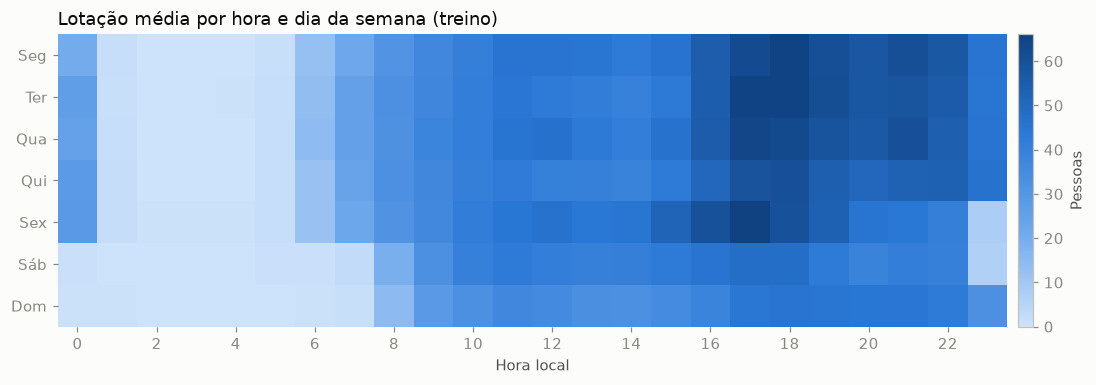

In [22]:
training_hourly = hourly.loc[:training_end]
training_readings = readings[readings["local_time"] <= training_end]

weekday_names = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
hour_weekday_mean = (
    training_hourly.assign(hour_of_day=training_hourly.index.hour, weekday=training_hourly.index.day_of_week)
    .pivot_table(index="weekday", columns="hour_of_day", values="people_observed", aggfunc="mean")
)
sequential_blues = LinearSegmentedColormap.from_list("sequential_blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(11, 3.6))
heatmap = ax.imshow(hour_weekday_mean.values, aspect="auto", cmap=sequential_blues, vmin=0)
ax.set_title("Lotação média por hora e dia da semana (treino)")
ax.set_xlabel("Hora local")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekday_names)
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(heatmap, ax=ax, label="Pessoas", pad=0.01)
fig.tight_layout()
plt.show()

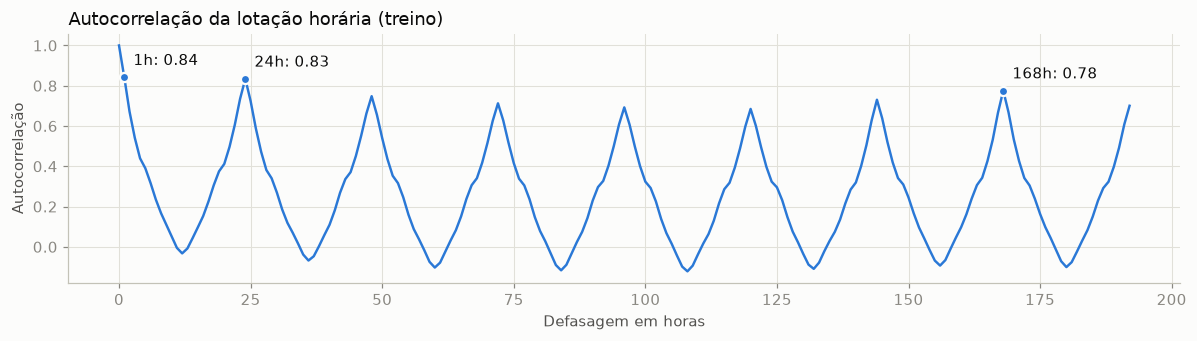

In [23]:
autocorrelation = acf(training_hourly["people_observed"], nlags=192, missing="conservative", fft=False)
highlighted_lags = {1: "1h", 24: "24h", 168: "168h"}

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(range(len(autocorrelation)), autocorrelation, color=BLUE, linewidth=1.6)
for lag, label in highlighted_lags.items():
    ax.scatter(lag, autocorrelation[lag], color=BLUE, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.annotate(f"{label}: {autocorrelation[lag]:.2f}", (lag, autocorrelation[lag]), xytext=(6, 8), textcoords="offset points", color=INK)
ax.set_title("Autocorrelação da lotação horária (treino)")
ax.set_xlabel("Defasagem em horas")
ax.set_ylabel("Autocorrelação")
fig.tight_layout()
plt.show()

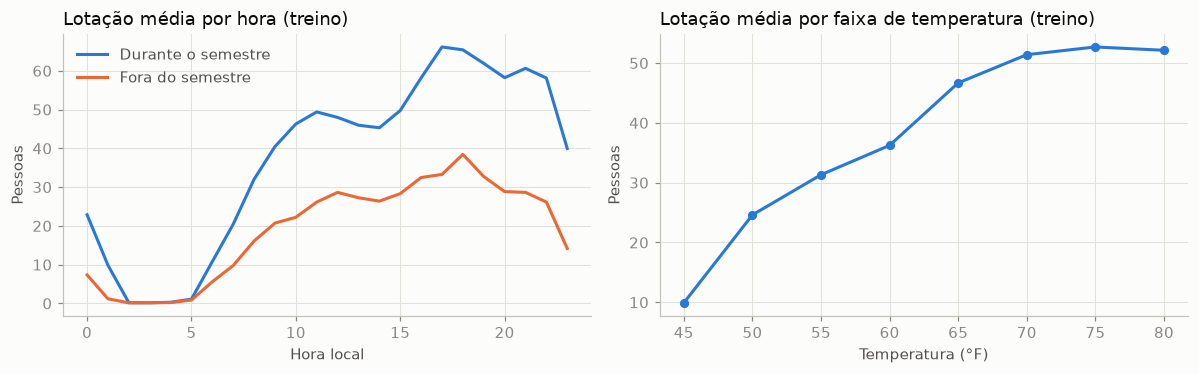

In [24]:
semester_profile = training_readings.groupby(["is_during_semester", "hour"])["number_people"].mean().unstack(level=0)
temperature_bins = training_readings["temperature"].div(5).round().mul(5)
temperature_profile = training_readings.groupby(temperature_bins)["number_people"].agg(["mean", "size"]).query("size >= 100")

fig, (semester_axis, temperature_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
semester_axis.plot(semester_profile.index, semester_profile[1], color=BLUE, linewidth=2, label="Durante o semestre")
semester_axis.plot(semester_profile.index, semester_profile[0], color=ORANGE, linewidth=2, label="Fora do semestre")
semester_axis.set_title("Lotação média por hora (treino)")
semester_axis.set_xlabel("Hora local")
semester_axis.set_ylabel("Pessoas")
semester_axis.legend(loc="upper left")
temperature_axis.plot(temperature_profile.index, temperature_profile["mean"], color=BLUE, linewidth=2, marker="o", markersize=5)
temperature_axis.set_title("Lotação média por faixa de temperatura (treino)")
temperature_axis.set_xlabel("Temperatura (°F)")
temperature_axis.set_ylabel("Pessoas")
fig.tight_layout()
plt.show()

**O que os gráficos mostram**

- **Ciclo diário:** a academia fica quase vazia entre 2h e 5h, enche ao longo do dia e atinge o pico por volta das 17h e 18h nos dias úteis.
- **Ciclo semanal:** sábados e domingos têm movimento menor e começam mais tarde. Na sexta e no sábado, o movimento cai mais cedo à noite, e o quadrado das 23h fica claro.
- **Autocorrelação:** ela vale 0,84 na defasagem de 1 hora, 0,83 em 24 horas e 0,78 em 168 horas. Os picos a cada 24 horas justificam as janelas de 24 e de 168 horas e as referências sazonais, e a volta do pico perto de 144 e 168 horas é o ciclo semanal.
- **Semestre:** no pico, a média chega a cerca de 66 pessoas durante o semestre (17h) e a cerca de 38 fora dele (18h).
- **Temperatura:** a lotação sobe de cerca de 10 pessoas a 45 °F para mais de 50 a partir de 70 °F. Isso é correlação, e não causa, porque a temperatura também acompanha a hora do dia e a estação do ano, que se misturam com o semestre.

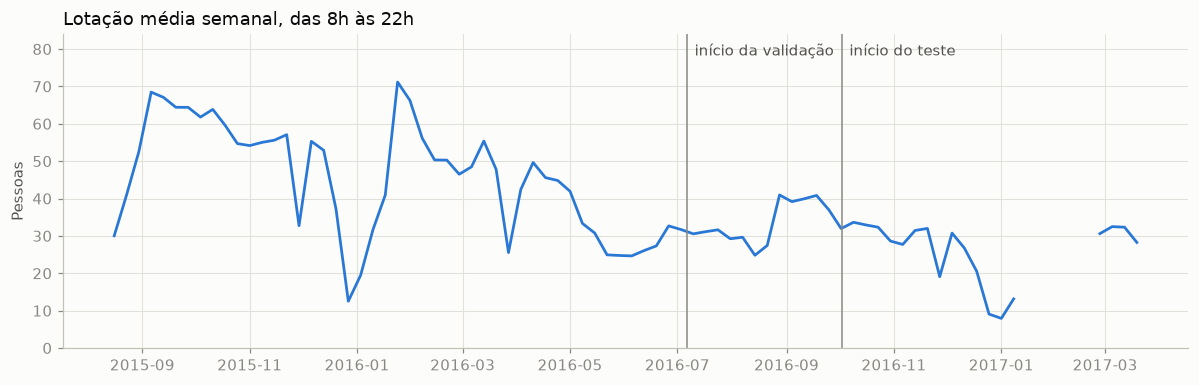

,mês,média_2015,média_2016,razão_2016_2015
0,9,65.63,38.04,0.58
1,10,58.97,31.46,0.53
2,11,49.92,27.79,0.56


,partição,média,mediana,desvio_padrão
0,treino,37.17,37.80,24.51
1,validação,23.08,24.83,16.56
2,teste,16.73,17.50,14.51


In [25]:
semester_daytime = readings[readings["hour"].between(8, 22) & readings["is_during_semester"].eq(1)]


def mean_people_in_month(year, month):
    is_selected = semester_daytime["local_time"].dt.year.eq(year) & semester_daytime["month"].eq(month)
    return semester_daytime.loc[is_selected, "number_people"].mean()


year_over_year = pd.DataFrame([
    {"mês": month, "média_2015": mean_people_in_month(2015, month), "média_2016": mean_people_in_month(2016, month)}
    for month in [9, 10, 11]
])
year_over_year["razão_2016_2015"] = year_over_year["média_2016"] / year_over_year["média_2015"]

partition_levels = pd.DataFrame([
    {
        "partição": name,
        "média": hourly.loc[dates, "people_observed"].mean(),
        "mediana": hourly.loc[dates, "people_observed"].median(),
        "desvio_padrão": hourly.loc[dates, "people_observed"].std(),
    }
    for name, dates in partitions.items()
])

weekly_daytime = readings[readings["hour"].between(8, 22)].set_index("local_time")["number_people"].resample("W").mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(weekly_daytime.index, weekly_daytime.values, color=BLUE, linewidth=1.8)
ax.set_ylim(0, weekly_daytime.max() * 1.18)
for label, boundary in [("início da validação", partitions["validação"].min()), ("início do teste", partitions["teste"].min())]:
    ax.axvline(boundary, color=MUTED_INK, linewidth=1)
    ax.annotate(label, (boundary, weekly_daytime.max() * 1.1), xytext=(5, 0), textcoords="offset points", color=SECONDARY_INK)
ax.set_title("Lotação média semanal, das 8h às 22h")
ax.set_ylabel("Pessoas")
fig.tight_layout()
plt.show()

display(year_over_year)
display(partition_levels)

**O nível da série muda ao longo do tempo.** Nos mesmos meses letivos, a lotação de 2016 ficou entre 53% e 58% da lotação de 2015. A média das datas-alvo cai de 37,17 pessoas no treino para 23,08 na validação e 16,73 no teste.

Os valores do gráfico semanal (30 a 40 pessoas na validação) são maiores que as médias da tabela porque o gráfico só considera das 8h às 22h, e a tabela inclui as madrugadas vazias.

A queda aparece por volta de maio de 2016, mesmo período em que as leituras ficam mais regulares (mediana de 6 leituras por hora, contra 5 antes) e as paradas noturnas de coleta deixam de ocorrer. O dataset não informa a causa, então não é possível dizer se houve mudança real de público ou mudança na forma de medir. Cerca de 80% do calendário do treino pertence ao regime antigo, enquanto a validação e o teste são do regime novo.

O risco é a rede aprender um nível mais alto do que o encontrado nos dados futuros. Esse efeito será medido pelo viés das previsões na validação.

## 5. Janelas e checagens contra vazamento

Cada exemplo usa horas anteriores à data-alvo para prever a lotação observada naquela hora, com avanço de uma hora por vez. Três configurações de histórico são construídas sobre as mesmas datas-alvo:

| Configuração | Histórico usado | Passos |
|---|---|---|
| `continua_24h` | As 24 horas anteriores | 24 |
| `continua_168h` | As 168 horas anteriores, uma semana completa | 168 |
| `dilatada_24h_7d` | As 24 horas anteriores, mais a mesma hora do dia de 2 a 7 dias antes | 30 |

As janelas contínuas de 24 e de 168 horas são as da comparação pedida na lauda. A janela dilatada é uma terceira candidata: ela mantém o detalhe do último dia e acrescenta só as horas que se repetem nos dias anteriores, em vez de todas as horas da semana. A defasagem de 24 horas já está dentro das 24 horas anteriores e não é repetida. Como todas as defasagens da dilatada estão dentro das 168 horas, as três configurações têm exatamente as mesmas datas-alvo.

Cada passo tem seis entradas: a lotação padronizada, o indicador de hora preenchida, e o seno e o cosseno da hora do dia e do dia da semana. Temperatura e período letivo ficam disponíveis como entradas opcionais. O padronizador é ajustado apenas com as observações do período de treino.

In [26]:
BASE_FEATURES = ["people", "is_imputed", "hour_sin", "hour_cos", "weekday_sin", "weekday_cos"]
OPTIONAL_FEATURES = ["temperature", "is_during_semester"]
WINDOW_CONFIGS = {
    "continua_24h": list(range(24, 0, -1)),
    "continua_168h": list(range(168, 0, -1)),
    "dilatada_24h_7d": [168, 144, 120, 96, 72, 48] + list(range(24, 0, -1)),
}

scaler = StandardScaler().fit(training_observed.dropna().to_numpy().reshape(-1, 1))
temperature_training = hourly.loc[:training_end].loc[hourly.loc[:training_end, "people_observed"].notna(), "temperature"]
temperature_scaler = StandardScaler().fit(temperature_training.to_numpy().reshape(-1, 1))


def to_people(scaled_values):
    return scaler.inverse_transform(np.asarray(scaled_values).reshape(-1, 1)).ravel()


def build_feature_matrix(frame, feature_names):
    hour_angle = 2 * np.pi * frame.index.hour.to_numpy() / 24
    weekday_angle = 2 * np.pi * frame.index.day_of_week.to_numpy() / 7
    columns = {
        "people": scaler.transform(frame[["people"]].to_numpy()).ravel(),
        "is_imputed": frame["is_imputed"].to_numpy(),
        "hour_sin": np.sin(hour_angle),
        "hour_cos": np.cos(hour_angle),
        "weekday_sin": np.sin(weekday_angle),
        "weekday_cos": np.cos(weekday_angle),
        "temperature": temperature_scaler.transform(frame[["temperature"]].to_numpy()).ravel(),
        "is_during_semester": frame["is_during_semester"].to_numpy(),
    }
    return np.column_stack([columns[name] for name in feature_names])


def build_examples(frame, dates, lags, feature_names=BASE_FEATURES):
    features = build_feature_matrix(frame, feature_names)
    scaled_targets = scaler.transform(frame[["people_observed"]].to_numpy()).ravel()
    positions = frame.index.get_indexer(dates)
    step_positions = positions[:, None] - np.asarray(lags)[None, :]
    return features[step_positions].astype(np.float32), scaled_targets[positions].astype(np.float32)


def eligible_targets(frame, lags):
    is_eligible = frame["people_observed"].notna().to_numpy()
    for lag in lags:
        is_eligible = is_eligible & frame["is_available"].shift(lag, fill_value=False).to_numpy()
    return frame.index[is_eligible]


targets_by_config = {name: eligible_targets(hourly, lags) for name, lags in WINDOW_CONFIGS.items()}
common_target_hours = targets_by_config["continua_24h"].intersection(targets_by_config["continua_168h"]).intersection(targets_by_config["dilatada_24h_7d"])
partitions_before_windows = partitions
partitions = split_partitions(common_target_hours)

examples = {
    name: {part: build_examples(hourly, partitions[part], lags) for part in ["treino", "validação"]}
    for name, lags in WINDOW_CONFIGS.items()
}

pd.DataFrame([
    {"configuração": name, "partição": part, "formato_entradas": str(inputs.shape), "formato_alvos": str(targets.shape)}
    for name, parts in examples.items()
    for part, (inputs, targets) in parts.items()
])

,configuração,partição,formato_entradas,formato_alvos
0,continua_24h,treino,"(5693, 24, 6)","(5693,)"
1,continua_24h,validação,"(1898, 24, 6)","(1898,)"
2,continua_168h,treino,"(5693, 168, 6)","(5693,)"
3,continua_168h,validação,"(1898, 168, 6)","(1898,)"
4,dilatada_24h_7d,treino,"(5693, 30, 6)","(5693,)"
5,dilatada_24h_7d,validação,"(1898, 30, 6)","(1898,)"


In [27]:
probe_date = pd.DatetimeIndex([partitions["validação"][0]])
probe_frame = hourly.copy()
probe_frame.loc[probe_date, "people_observed"] += 50
probe_frame["people"] = fill_with_profile(probe_frame, training_end)
all_features = BASE_FEATURES + OPTIONAL_FEATURES

first_training_dates = partitions["treino"][:3]
dilated_inputs, _ = build_examples(hourly, first_training_dates, WINDOW_CONFIGS["dilatada_24h_7d"])
first_date = first_training_dates[0]
oldest_value = hourly.loc[first_date - pd.Timedelta(hours=168), "people"]
newest_value = hourly.loc[first_date - pd.Timedelta(hours=1), "people"]

training_temperature_count = int(hourly.loc[:training_end, "people_observed"].notna().sum())

leakage_checks = {
    "Partições em ordem cronológica e sem sobreposição": (
        partitions["treino"].max() < partitions["validação"].min()
        and partitions["validação"].max() < partitions["teste"].min()
    ),
    "Teste com pelo menos 20% das datas-alvo": len(partitions["teste"]) / len(common_target_hours) >= 0.2,
    "As partições não mudaram depois de combinar as três configurações": all(
        partitions[name].equals(partitions_before_windows[name]) for name in partitions
    ),
    "As datas-alvo comuns são as da janela contínua de 168h": common_target_hours.equals(targets_by_config["continua_168h"]),
    "Todas as datas-alvo são valores realmente observados": hourly.loc[common_target_hours, "people_observed"].notna().all(),
    "Formato das entradas igual ao número de passos de cada configuração": all(
        build_examples(hourly, first_training_dates, lags)[0].shape == (3, len(lags), len(BASE_FEATURES))
        for lags in WINDOW_CONFIGS.values()
    ),
    "Janela dilatada com 30 passos, do mais antigo (168h) ao mais recente (1h)": (
        len(WINDOW_CONFIGS["dilatada_24h_7d"]) == 30
        and np.isclose(dilated_inputs[0, 0, 0], scaler.transform([[oldest_value]])[0, 0])
        and np.isclose(dilated_inputs[0, -1, 0], scaler.transform([[newest_value]])[0, 0])
    ),
    "Mesmos alvos nas três configurações em cada partição": all(
        np.array_equal(examples["continua_24h"][part][1], examples[name][part][1])
        for name in WINDOW_CONFIGS
        for part in ["treino", "validação"]
    ),
    "Nenhuma entrada vazia nas janelas, com e sem atributos opcionais": all(
        np.isfinite(build_examples(hourly, partitions[part], lags, features)[0]).all()
        for lags in WINDOW_CONFIGS.values()
        for features in [BASE_FEATURES, all_features]
        for part in ["treino", "validação"]
    ),
    "Alterar o alvo não muda as entradas, em nenhuma configuração": all(
        np.array_equal(
            build_examples(hourly, probe_date, lags, features)[0],
            build_examples(probe_frame, probe_date, lags, features)[0],
        )
        for lags in WINDOW_CONFIGS.values()
        for features in [BASE_FEATURES, all_features]
    ),
    "Alterar o alvo muda o valor previsto como alvo": not np.array_equal(
        build_examples(hourly, probe_date, WINDOW_CONFIGS["continua_24h"])[1],
        build_examples(probe_frame, probe_date, WINDOW_CONFIGS["continua_24h"])[1],
    ),
    "Padronizadores ajustados só com as observações de treino": (
        scaler.n_samples_seen_ == training_observed.notna().sum()
        and np.isclose(scaler.mean_[0], training_observed.dropna().mean())
        and temperature_scaler.n_samples_seen_ == training_temperature_count
    ),
}
assert all(leakage_checks.values())

pd.Series(leakage_checks, name="passou").to_frame()

,passou
Partições em ordem cronológica e sem sobreposição,True
Teste com pelo menos 20% das datas-alvo,True
As partições não mudaram depois de combinar as três configurações,True
As datas-alvo comuns são as da janela contínua de 168h,True
Todas as datas-alvo são valores realmente observados,True
Formato das entradas igual ao número de passos de cada configuração,True
"Janela dilatada com 30 passos, do mais antigo (168h) ao mais recente (1h)",True
Mesmos alvos nas três configurações em cada partição,True
"Nenhuma entrada vazia nas janelas, com e sem atributos opcionais",True
"Alterar o alvo não muda as entradas, em nenhuma configuração",True
